Final Mean 1: 3.0035423758384177
Final Mean 2: 9.996457624161582

Final Weight 1: 0.4999999999999999
Final Weight 2: 0.5

Cluster Assignments:
[1 1 1 1 1 2 2 2 2 2]


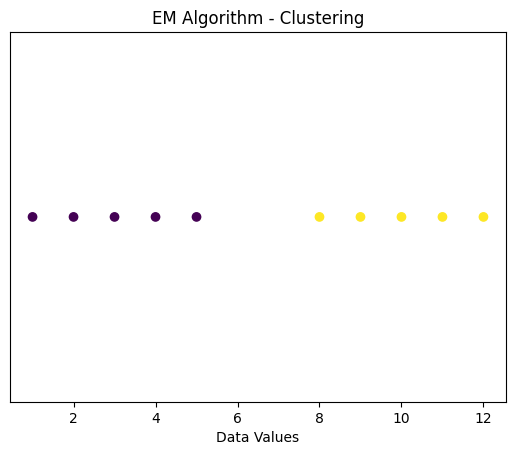

In [1]:

# Experiment 10: Expectation Maximization Algorithm

# Step 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt

# Step 2: Create dataset
X = np.array([1, 2, 3, 4, 5, 8, 9, 10, 11, 12])

# Step 3: Initialize parameters
mean1 = 2.0
mean2 = 10.0

var1 = 2.0
var2 = 2.0

weight1 = 0.5
weight2 = 0.5

# Step 4: Gaussian probability function
def gaussian(x, mean, var):
    return (1 / np.sqrt(2 * np.pi * var)) * np.exp(
        -((x - mean) ** 2) / (2 * var)
    )

# Step 5: Apply EM algorithm
for i in range(20):

    # E-step: Calculate probabilities
    p1 = weight1 * gaussian(X, mean1, var1)
    p2 = weight2 * gaussian(X, mean2, var2)

    responsibility1 = p1 / (p1 + p2)
    responsibility2 = p2 / (p1 + p2)

    # M-step: Update parameters
    weight1 = np.mean(responsibility1)
    weight2 = np.mean(responsibility2)

    mean1 = np.sum(responsibility1 * X) / np.sum(responsibility1)
    mean2 = np.sum(responsibility2 * X) / np.sum(responsibility2)

    var1 = np.sum(responsibility1 * (X - mean1) ** 2) / np.sum(responsibility1)
    var2 = np.sum(responsibility2 * (X - mean2) ** 2) / np.sum(responsibility2)

# Step 6: Display results
print("Final Mean 1:", mean1)
print("Final Mean 2:", mean2)

print("\nFinal Weight 1:", weight1)
print("Final Weight 2:", weight2)

# Step 7: Assign clusters
clusters = np.where(responsibility1 > responsibility2, 1, 2)

print("\nCluster Assignments:")
print(clusters)

# Step 8: Display graph
plt.scatter(X, np.zeros(len(X)), c=clusters)
plt.xlabel("Data Values")
plt.title("EM Algorithm - Clustering")
plt.yticks([])
plt.show()
